# Mini-projet 02 — KNN sur UCI Dry Bean

**Auteur :** (partie KNN de l'equipe)
**Date :** 2026-11-07
**Dataset :** UCI Dry Bean Dataset (13 611 grains, 16 caracteristiques, 7 varietes)

## Objectif
Construire, regler et evaluer un modele **K plus proches voisins (KNN)** pour reconnaitre 7 varietes de haricots a partir de 16 mesures morphologiques — en respectant **la regle d'or de l'equipe** (seed 42, split 80/20 stratifie, Pipeline standardise, CV 5-fold stratifiee, F1 macro).

## Plan
1. Import et configuration
2. Chargement et exploration du dataset
3. Split stratifie train/test (80/20)
4. **Experience de standardisation** : avec vs sans `StandardScaler`
5. **Tuning des hyperparametres** : `GridSearchCV` sur k, distance, poids
6. **Evaluation finale** sur le test (une seule fois)
7. **BONUS 1** : baseline naive (`DummyClassifier`)
8. **BONUS 2** : visualisation PCA 2D
9. **BONUS 3** : courbe d'apprentissage
10. **BONUS 4** : temps de prediction et analyse d'erreurs
11. Conclusion

> *Toutes les explications pedagogiques detaillees sont dans `EXPLICATIONS_DETAILLEES.md`.*


## 1. Import et configuration

On importe toutes les bibliotheques et on fixe la graine aleatoire a **42** (regle d'or).

In [1]:
import time, warnings, os
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_val_score,
    GridSearchCV, learning_curve,
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix,
)

SEED = 42            # graine aleatoire universelle (regle d'or)
TEST_SIZE = 0.20     # 80/20
N_SPLITS = 5         # 5-fold CV
sns.set_theme(style="whitegrid")
np.random.seed(SEED)

print("Librairies chargees, graine aleatoire =", SEED)

Librairies chargees, graine aleatoire = 42


## 2. Chargement et exploration du dataset

Le dataset Dry Bean contient **13 611 grains** et **16 mesures geometriques** + 1 colonne `Class` (la variete).

In [2]:
df = pd.read_csv("Dry_Bean_Dataset.csv")
df.columns = [c.lstrip("\ufeff").strip() for c in df.columns]
print("Dimensions :", df.shape)
print("Valeurs manquantes :", df.isna().sum().sum())
df.head()

Dimensions : (13611, 17)
Valeurs manquantes : 0


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [3]:
counts = df["Class"].value_counts()
print(counts)
print(f"\nClasse la plus rare   : {counts.idxmin()} ({counts.min()} grains, {counts.min()/len(df)*100:.1f}%)")
print(f"Classe la plus frequente : {counts.idxmax()} ({counts.max()} grains, {counts.max()/len(df)*100:.1f}%)")
print("=> Classes DESEQUILIBREES : d'ou le choix du F1 macro.")

Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64

Classe la plus rare   : BOMBAY (522 grains, 3.8%)
Classe la plus frequente : DERMASON (3546 grains, 26.1%)
=> Classes DESEQUILIBREES : d'ou le choix du F1 macro.


In [4]:
# Les 16 variables et leurs echelles
desc = df.drop(columns=["Class"]).describe().T[["min", "max", "mean", "std"]]
print(desc.round(3))

                       min         max       mean        std
Area             20420.000  254616.000  53048.285  29324.096
Perimeter          524.736    1985.370    855.283    214.290
MajorAxisLength    183.601     738.860    320.142     85.694
MinorAxisLength    122.513     460.198    202.271     44.970
AspectRation         1.025       2.430      1.583      0.247
Eccentricity         0.219       0.911      0.751      0.092
ConvexArea       20684.000  263261.000  53768.200  29774.916
EquivDiameter      161.244     569.374    253.064     59.177
Extent               0.555       0.866      0.750      0.049
Solidity             0.919       0.995      0.987      0.005
roundness            0.490       0.991      0.873      0.060
Compactness          0.641       0.987      0.800      0.062
ShapeFactor1         0.003       0.010      0.007      0.001
ShapeFactor2         0.001       0.004      0.002      0.001
ShapeFactor3         0.410       0.975      0.644      0.099
ShapeFactor4         0.9

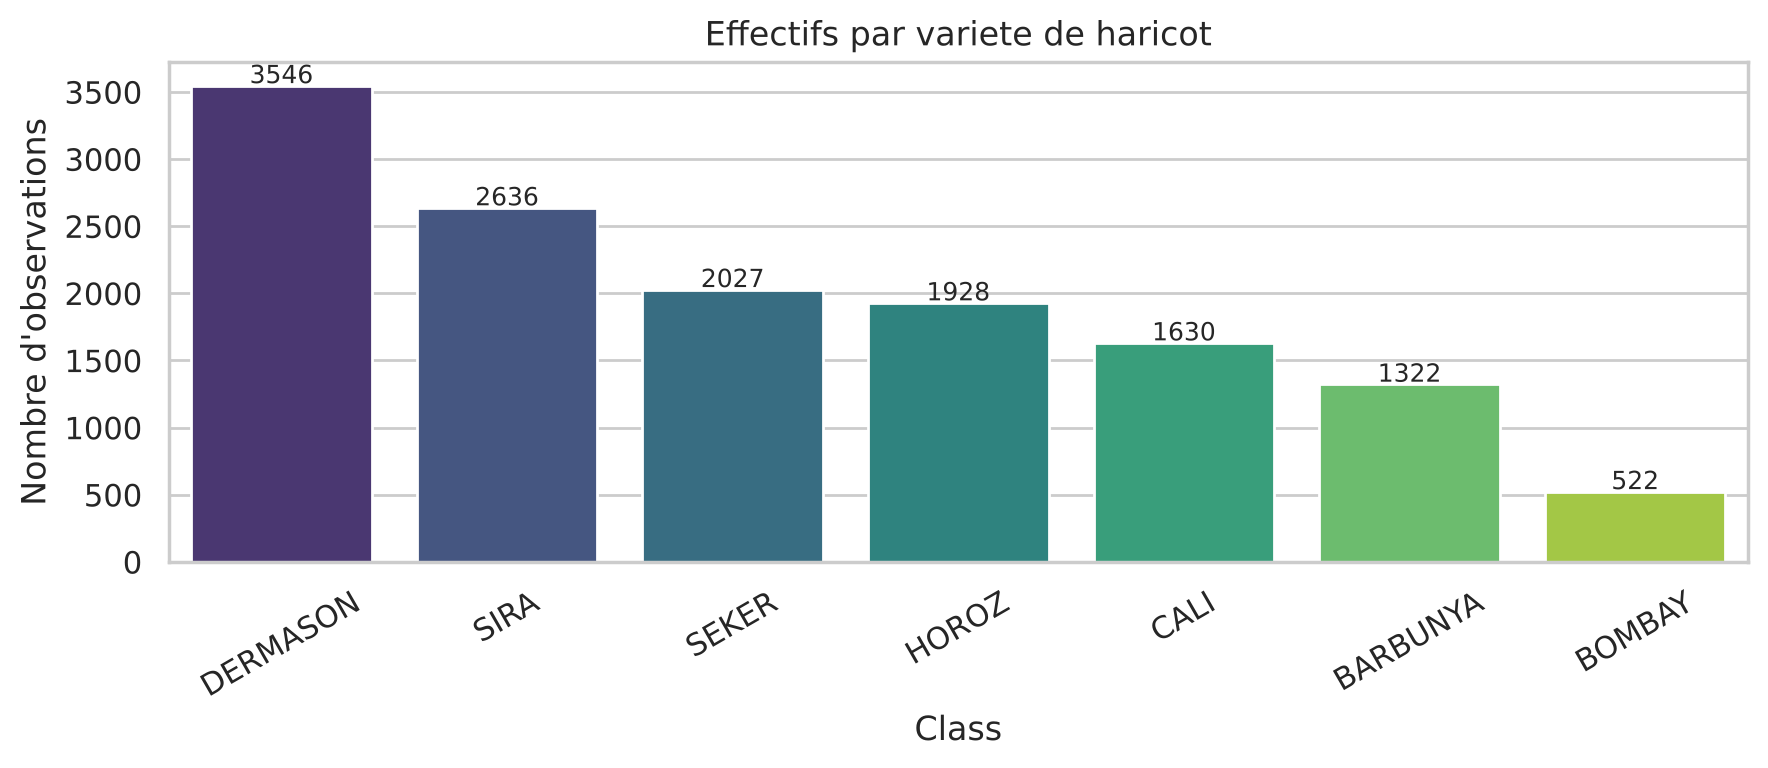

In [5]:
# Visualisation : effectifs par variete
plt.figure(figsize=(9, 4))
ax = sns.barplot(x=counts.index, y=counts.values, hue=counts.index, palette="viridis", legend=False)
for i, v in enumerate(counts.values):
    ax.text(i, v + 20, str(v), ha="center", fontsize=9)
plt.title("Effectifs par variete de haricot")
plt.ylabel("Nombre d'observations"); plt.xticks(rotation=30)
plt.tight_layout(); plt.show()

**Lecture :**
- `DERMASON` = 26 % des grains, `BOMBAY` = 3.8 % seulement → classes **tres desequilibrees**.
- Les echelles vont de `Area` ≈ 50 000 a `Solidity` ≈ 0.99 → **standardiser est indispensable pour KNN** (qui calcule des distances).

## 3. Split stratifie train/test (80/20)

`stratify=y` garde les memes proportions de classes dans train et test. `random_state=42` rend le decoupage reproductible.

In [6]:
FEATURES = [c for c in df.columns if c != "Class"]
X = df[FEATURES]
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=SEED, stratify=y,
)
print(f"Train : {len(X_train)} grains | Test : {len(X_test)} grains")
pd.DataFrame({
    "train_%": (y_train.value_counts(normalize=True) * 100).round(2),
    "test_%" : (y_test.value_counts(normalize=True)  * 100).round(2),
})

Train : 10888 grains | Test : 2723 grains


,train_%,test_%
Class,,
DERMASON,26.06,26.04
SIRA,19.37,19.35
SEKER,14.89,14.91
HOROZ,14.16,14.18
CALI,11.98,11.97
BARBUNYA,9.71,9.73
BOMBAY,3.84,3.82


**Verification :** les proportions sont identiques a 0.03 % pres entre train et test → le `stratify` fonctionne.

## 4. Experience de standardisation (CV 5-fold sur le train)

**Hypothese :** KNN calcule des distances. Une variable a grande amplitude (`Area` ≈ 50 000) domine une variable a petite amplitude (`Solidity` ≈ 0.99). Standardiser (moyenne 0, ecart-type 1) devrait **enormement** aider.

On compare deux configurations identiques sauf le `StandardScaler`.

In [7]:
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

rows = []
for name, use_scaler in [("Sans StandardScaler", False), ("Avec StandardScaler", True)]:
    steps = ([("scaler", StandardScaler())] if use_scaler else []) + [("knn", KNeighborsClassifier(n_neighbors=5))]
    pipe = Pipeline(steps)
    f1s = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=-1)
    rows.append({"config": name, "F1_macro_moy": f1s.mean(), "F1_macro_std": f1s.std()})
    print(f"{name:22s} | F1 macro = {f1s.mean():.4f}  (+/- {f1s.std():.4f})")

res_scaling = pd.DataFrame(rows)
gain = res_scaling.loc[1, "F1_macro_moy"] - res_scaling.loc[0, "F1_macro_moy"]
print(f"\nGain grace a la standardisation : {gain:+.4f} points de F1 macro")

Sans StandardScaler    | F1 macro = 0.7138  (+/- 0.0079)


Avec StandardScaler    | F1 macro = 0.9355  (+/- 0.0050)

Gain grace a la standardisation : +0.2217 points de F1 macro


**Verdict :** la standardisation fait gagner **environ +0.22 points de F1 macro**. On la garde dans tous les pipelines qui suivent. Et on l'utilise **dans un `Pipeline`** pour eviter la **fuite de donnees** (le scaler est appris sur chaque sous-train des 5 plis, jamais sur le test).

## 5. Tuning par `GridSearchCV`

On teste **60 combinaisons** × 5 plis = **300 entrainements**, scoring = **F1 macro**.

- `n_neighbors` : {1, 3, 5, 7, 9, 11, 15, 21, 31, 41}
- `metric` : {euclidean, manhattan, chebyshev}
- `weights` : {uniform, distance}

In [8]:
pipe = Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier())])

param_grid = {
    "knn__n_neighbors": [1, 3, 5, 7, 9, 11, 15, 21, 31, 41],
    "knn__metric":      ["euclidean", "manhattan", "chebyshev"],
    "knn__weights":     ["uniform", "distance"],
}

t0 = time.time()
grid = GridSearchCV(pipe, param_grid, cv=cv, scoring="f1_macro", n_jobs=-1, refit=True)
grid.fit(X_train, y_train)
print(f"Duree : {time.time()-t0:.1f} s")
print(f"\nMeilleurs hyperparametres : {grid.best_params_}")
print(f"Meilleur F1 macro en CV   : {grid.best_score_:.4f}")

Duree : 24.2 s

Meilleurs hyperparametres : {'knn__metric': 'euclidean', 'knn__n_neighbors': 9, 'knn__weights': 'distance'}
Meilleur F1 macro en CV   : 0.9382


In [9]:
# Top 5 des combinaisons
cvres = pd.DataFrame(grid.cv_results_).rename(columns={
    "param_knn__n_neighbors": "k", "param_knn__metric": "distance", "param_knn__weights": "poids",
})[["k", "distance", "poids", "mean_test_score", "std_test_score", "rank_test_score"]]
cvres.sort_values("rank_test_score").head(5).round(4)

,k,distance,poids,mean_test_score,std_test_score,rank_test_score
9,9,euclidean,distance,0.9382,0.0043,1
15,21,euclidean,distance,0.9381,0.0046,2
11,11,euclidean,distance,0.9376,0.0060,3
8,9,euclidean,uniform,0.9373,0.0043,4
10,11,euclidean,uniform,0.9372,0.0059,5


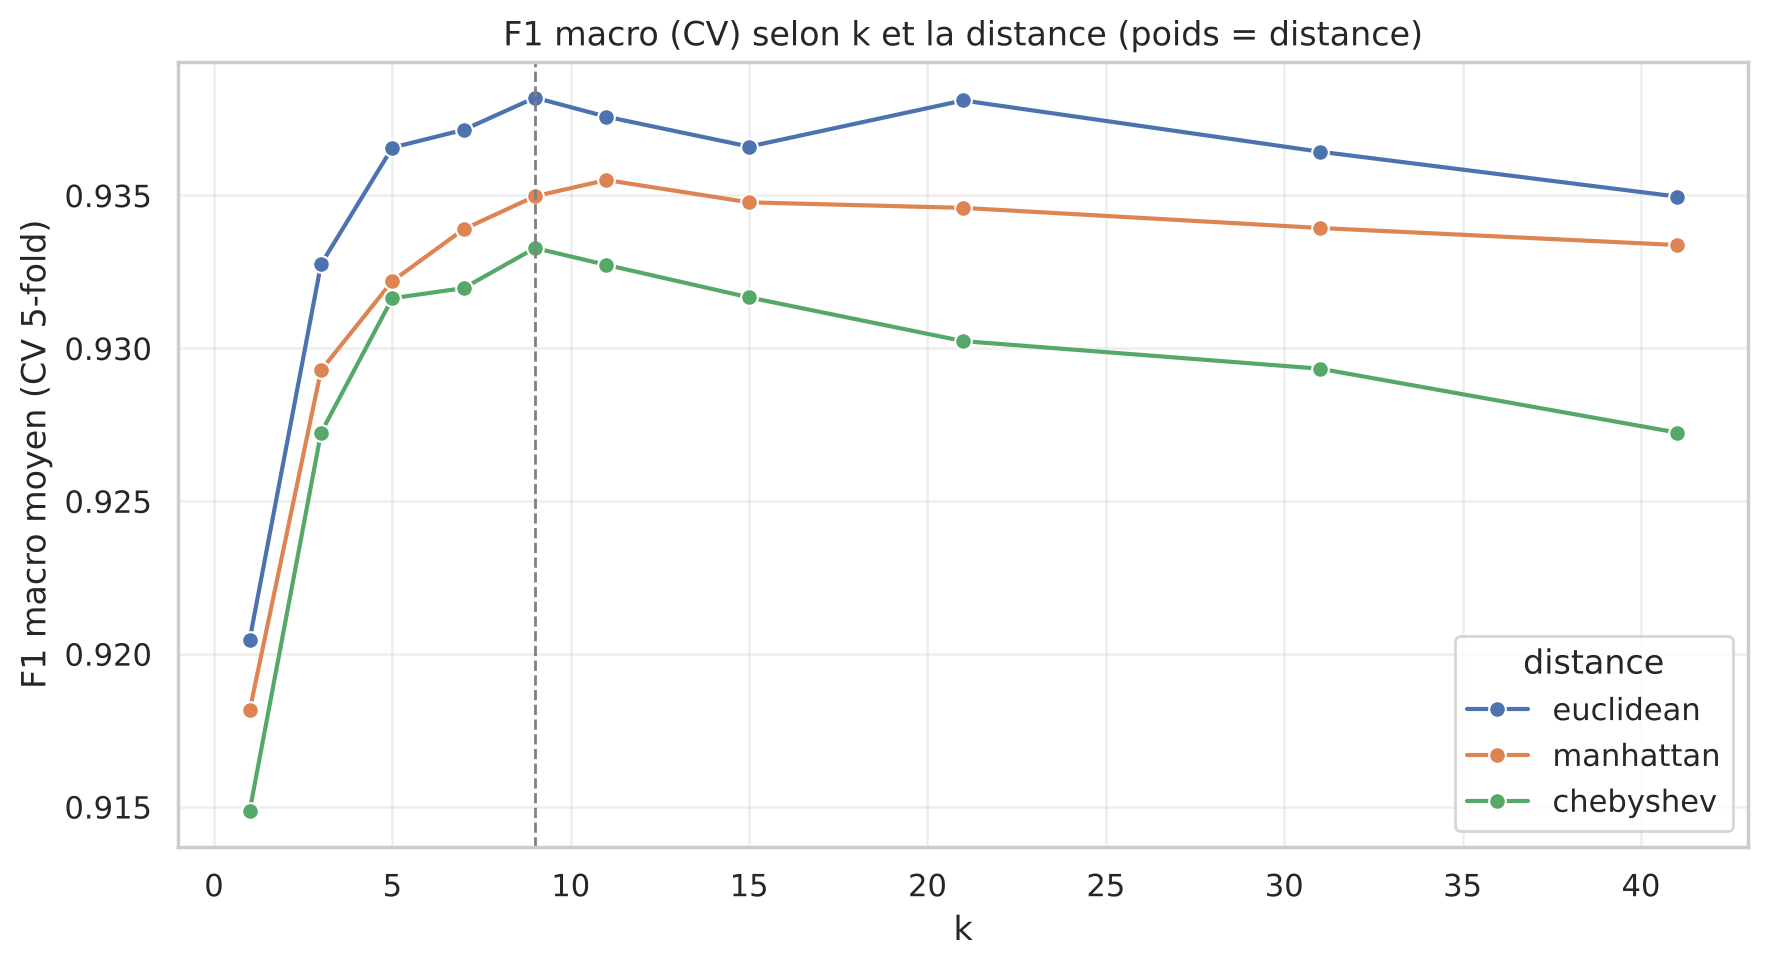

In [10]:
# Courbe F1 vs k, une courbe par distance (poids = meilleur poids)
best_w = grid.best_params_["knn__weights"]
sub = cvres[cvres["poids"] == best_w].copy()
sub["k"] = sub["k"].astype(int)

plt.figure(figsize=(9, 5))
sns.lineplot(data=sub, x="k", y="mean_test_score", hue="distance", marker="o")
plt.axvline(grid.best_params_["knn__n_neighbors"], color="grey", ls="--", lw=1)
plt.title(f"F1 macro (CV) selon k et la distance (poids = {best_w})")
plt.ylabel("F1 macro moyen (CV 5-fold)"); plt.xlabel("k")
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## 6. Evaluation finale sur le test (une seule fois)

C'est l'etape OU on utilise le test set. On ne peut le faire **qu'une fois**, avec le meilleur modele deja choisi par le `GridSearchCV`.

In [11]:
best = grid.best_estimator_
y_pred = best.predict(X_test)

acc  = accuracy_score(y_test, y_pred)
f1m  = f1_score(y_test, y_pred, average="macro")
prm  = precision_score(y_test, y_pred, average="macro")
rcm  = recall_score(y_test, y_pred, average="macro")

print(f"Accuracy        : {acc:.4f}")
print(f"Precision macro : {prm:.4f}")
print(f"Rappel macro    : {rcm:.4f}")
print(f"F1-score macro  : {f1m:.4f}")

Accuracy        : 0.9174
Precision macro : 0.9328
Rappel macro    : 0.9279
F1-score macro  : 0.9300


In [12]:
# F1 par variete
labels = sorted(y_test.unique())
report = classification_report(y_test, y_pred, labels=labels, output_dict=True, zero_division=0)
per_class = pd.DataFrame(report).T.loc[labels].rename(
    columns={"precision": "precision", "recall": "rappel", "f1-score": "F1", "support": "effectif"})
per_class["effectif"] = per_class["effectif"].astype(int)
per_class.round(4)

,precision,rappel,F1,effectif
BARBUNYA,0.9544,0.8679,0.9091,265
BOMBAY,1.0000,1.0000,1.0000,104
CALI,0.9196,0.9479,0.9335,326
DERMASON,0.9134,0.9069,0.9101,709
HOROZ,0.9584,0.9560,0.9572,386
SEKER,0.9435,0.9458,0.9446,406
SIRA,0.8407,0.8710,0.8555,527


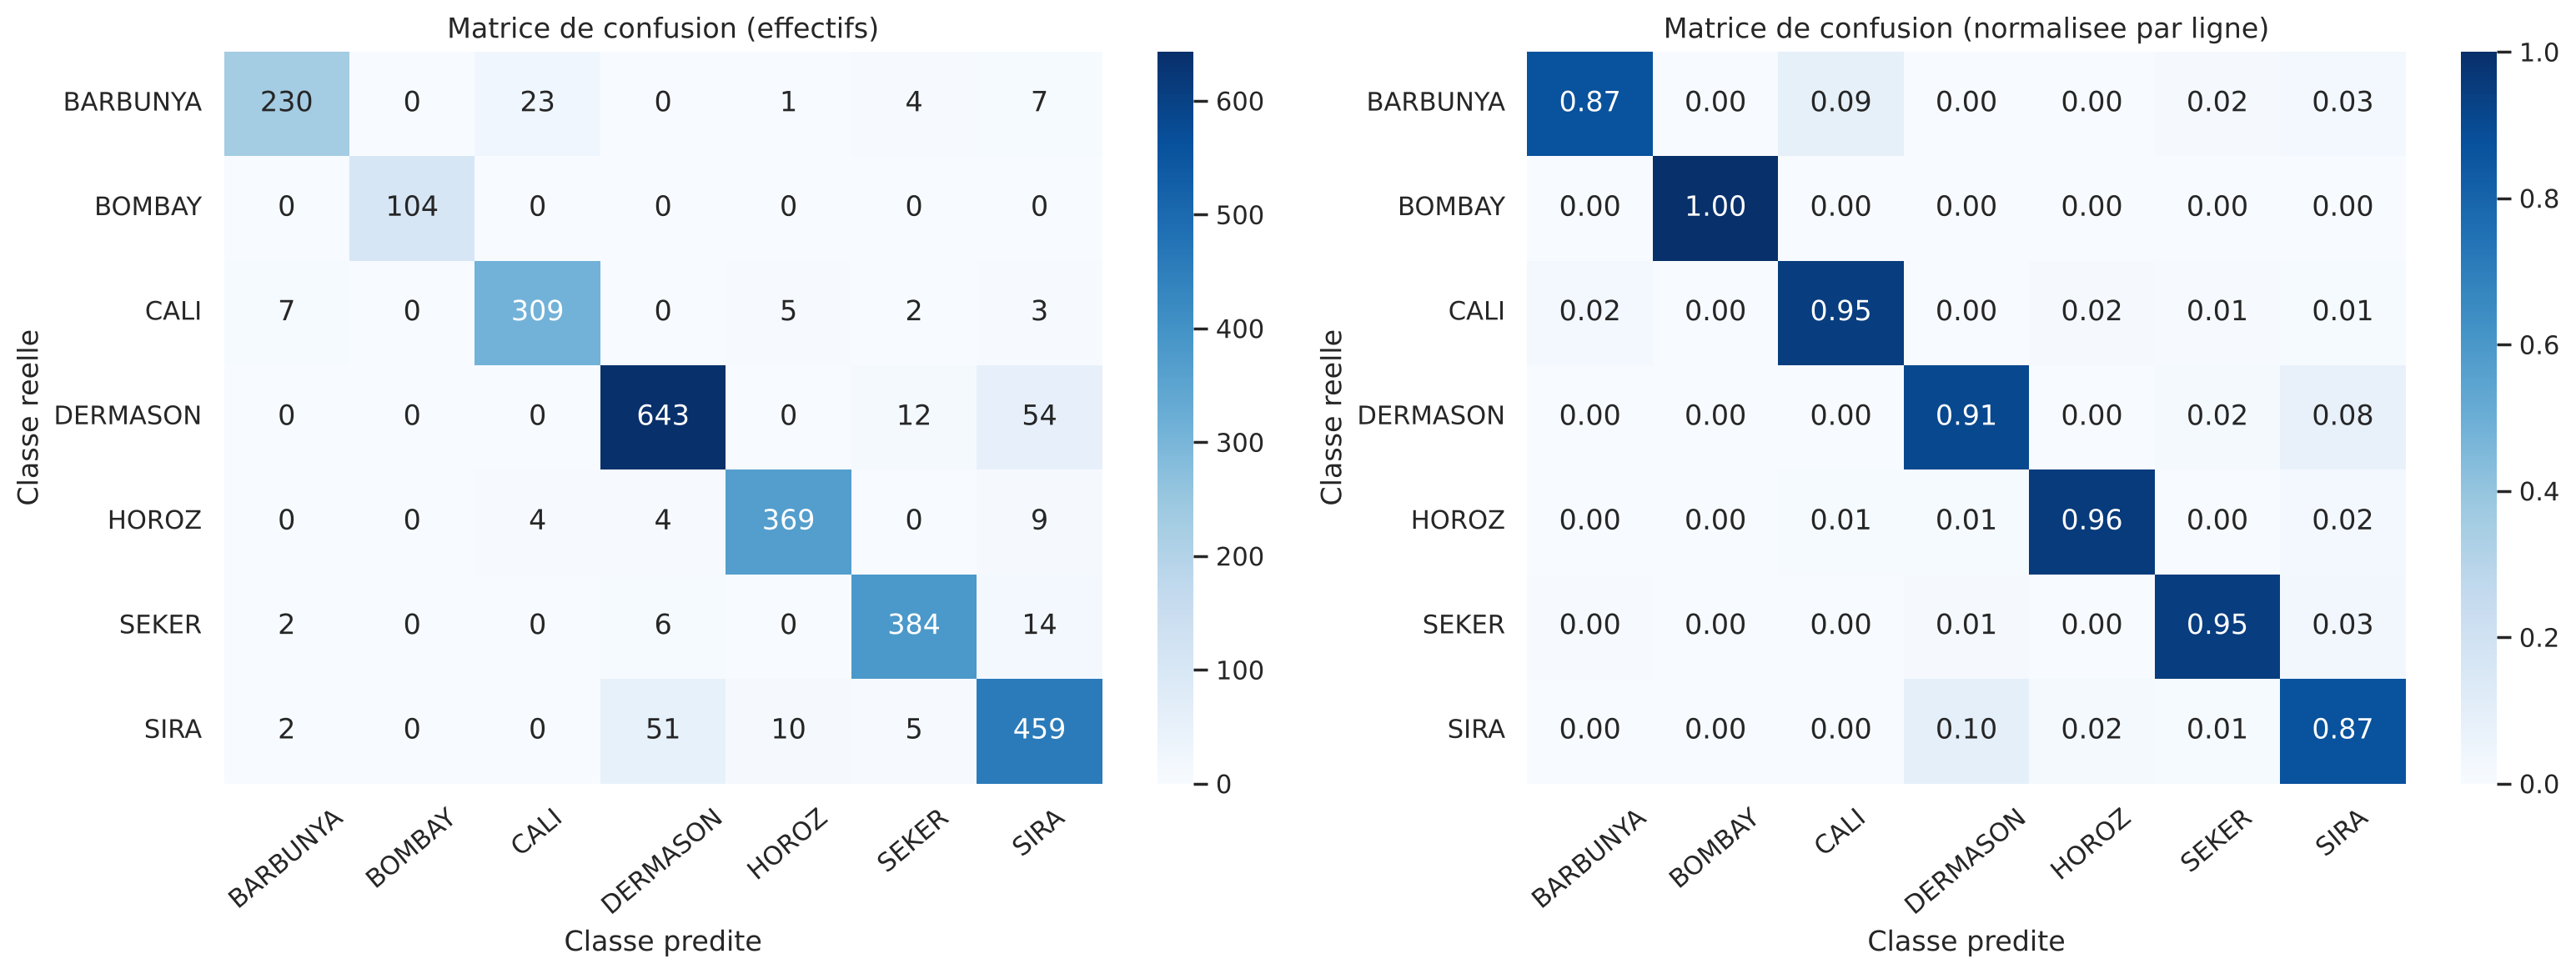

In [13]:
# Matrice de confusion
cm = confusion_matrix(y_test, y_pred, labels=labels)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels, yticklabels=labels, ax=axes[0])
axes[0].set_title("Matrice de confusion (effectifs)")
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
            xticklabels=labels, yticklabels=labels, ax=axes[1])
axes[1].set_title("Matrice de confusion (normalisee par ligne)")
for ax in axes:
    ax.set_xlabel("Classe predite"); ax.set_ylabel("Classe reelle"); ax.tick_params(axis="x", rotation=40)
plt.tight_layout(); plt.show()

**Lecture :**
- `BOMBAY` : F1 = 1.00 → aucune erreur, aucune autre classe prise pour BOMBAY.
- `SIRA` et `DERMASON` : grosse confusion mutuelle (environ 100 erreurs reciproques). Ces deux varietes ont une morphologie tres proche.

## 7. BONUS 1 — Baseline naive (`DummyClassifier`)

**Question importante :** notre F1 macro de 0.93 est-il reellement bon, ou n'importe quel modele l'obtiendrait ?

Reponse : on compare a trois modeles **stupides** qui ne regardent meme pas les donnees d'entree.

In [14]:
rows = []
for strat in ["most_frequent", "stratified", "uniform"]:
    clf = DummyClassifier(strategy=strat, random_state=SEED).fit(X_train, y_train)
    y_pred_d = clf.predict(X_test)
    rows.append({
        "strategie": strat,
        "accuracy": accuracy_score(y_test, y_pred_d),
        "F1_macro": f1_score(y_test, y_pred_d, average="macro"),
    })
baseline = pd.DataFrame(rows)
baseline["notre_KNN"] = f1m
baseline.round(4)

,strategie,accuracy,F1_macro,notre_KNN
0,most_frequent,0.2604,0.0590,0.93
1,stratified,0.1763,0.1470,0.93
2,uniform,0.1392,0.1332,0.93


**Interpretation :** le meilleur des modeles bidons (`stratified`) plafonne a F1 macro ≈ 0.15. Notre KNN a **0.93** est donc **environ 6x au-dessus du hasard** → il apprend reellement quelque chose.

## 8. BONUS 2 — Visualisation PCA 2D

On a 16 dimensions, impossible a visualiser. L'**ACP** (PCA) construit 2 nouveaux axes (combinaisons lineaires des 16 originaux) qui capturent le maximum de variance. On projette tout le monde dessus pour voir **a l'œil nu** comment les classes se melangent.

PC1 explique 55.5% de la variance
PC2 explique 26.4% de la variance
Total 2 axes : 81.9% (bonne qualite)


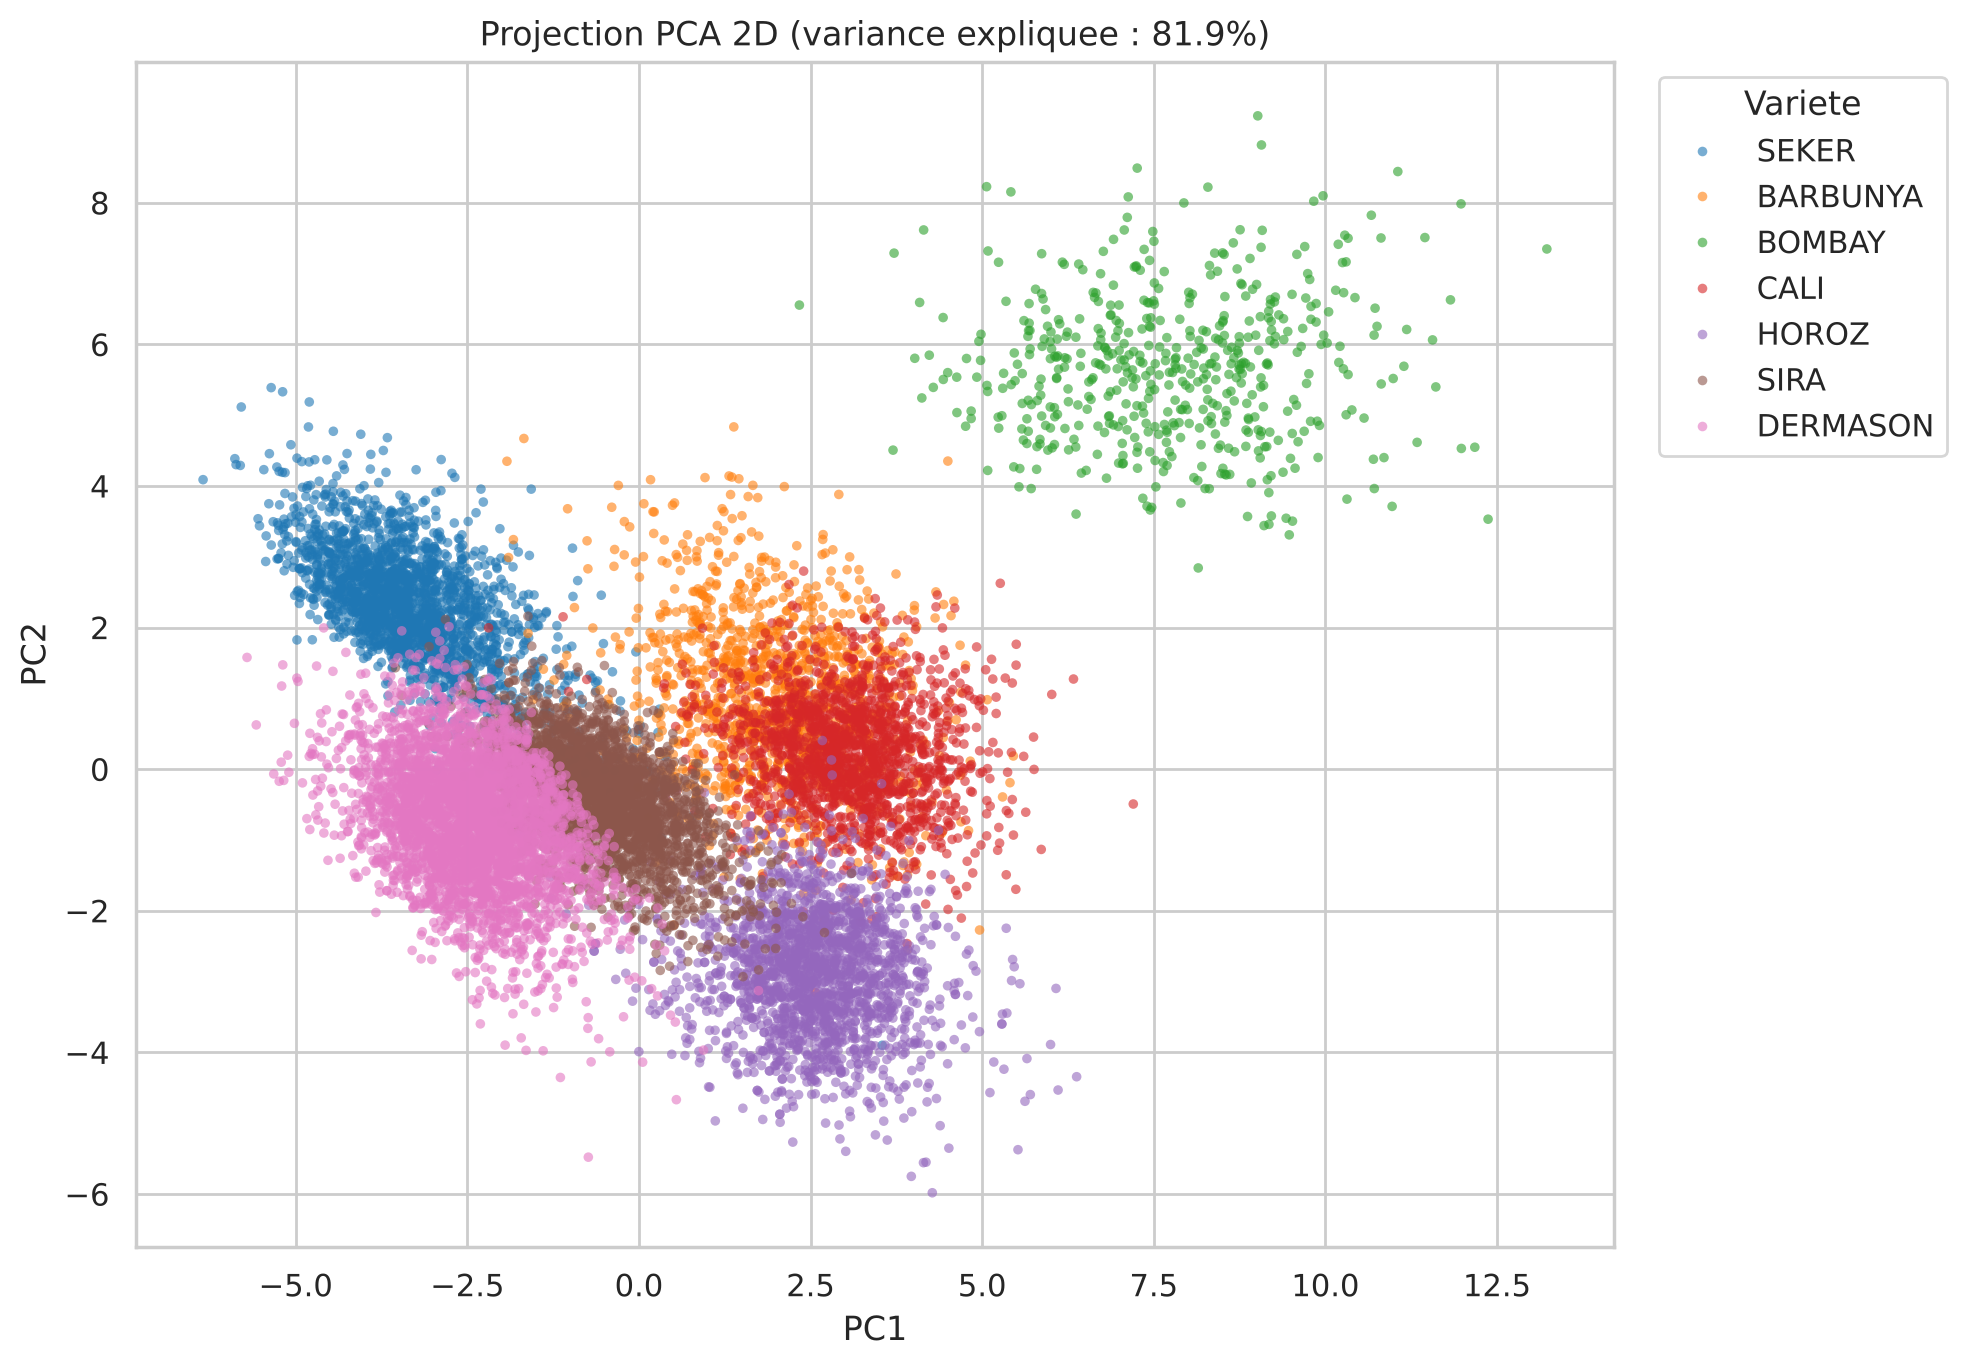

In [15]:
Xs = StandardScaler().fit_transform(X)
pca = PCA(n_components=2, random_state=SEED)
Z = pca.fit_transform(Xs)
print(f"PC1 explique {pca.explained_variance_ratio_[0]*100:.1f}% de la variance")
print(f"PC2 explique {pca.explained_variance_ratio_[1]*100:.1f}% de la variance")
print(f"Total 2 axes : {pca.explained_variance_ratio_.sum()*100:.1f}% (bonne qualite)")

df_pca = pd.DataFrame({"PC1": Z[:, 0], "PC2": Z[:, 1], "variete": y.values})
plt.figure(figsize=(10, 7))
sns.scatterplot(data=df_pca, x="PC1", y="PC2", hue="variete",
                palette="tab10", s=12, alpha=0.6, edgecolor="none")
plt.title(f"Projection PCA 2D (variance expliquee : {pca.explained_variance_ratio_.sum()*100:.1f}%)")
plt.legend(title="Variete", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()

**Lecture :** on voit nettement
- `BOMBAY` tres a l'ecart (grains enormes) → F1 = 1.00, c'etait previsible,
- `DERMASON` et `SIRA` se chevauchent presque completement → c'est **exactement** la confusion observee dans la matrice de confusion.

## 9. BONUS 3 — Courbe d'apprentissage

**Question :** aurait-on besoin de plus de donnees pour faire mieux ?

On refait tourner le meilleur modele avec **10 %, 23 %, ..., 100 %** du train, en CV. On trace :
- F1 sur le train (reussite sur les donnees vues)
- F1 en validation (reussite sur les donnees non vues)

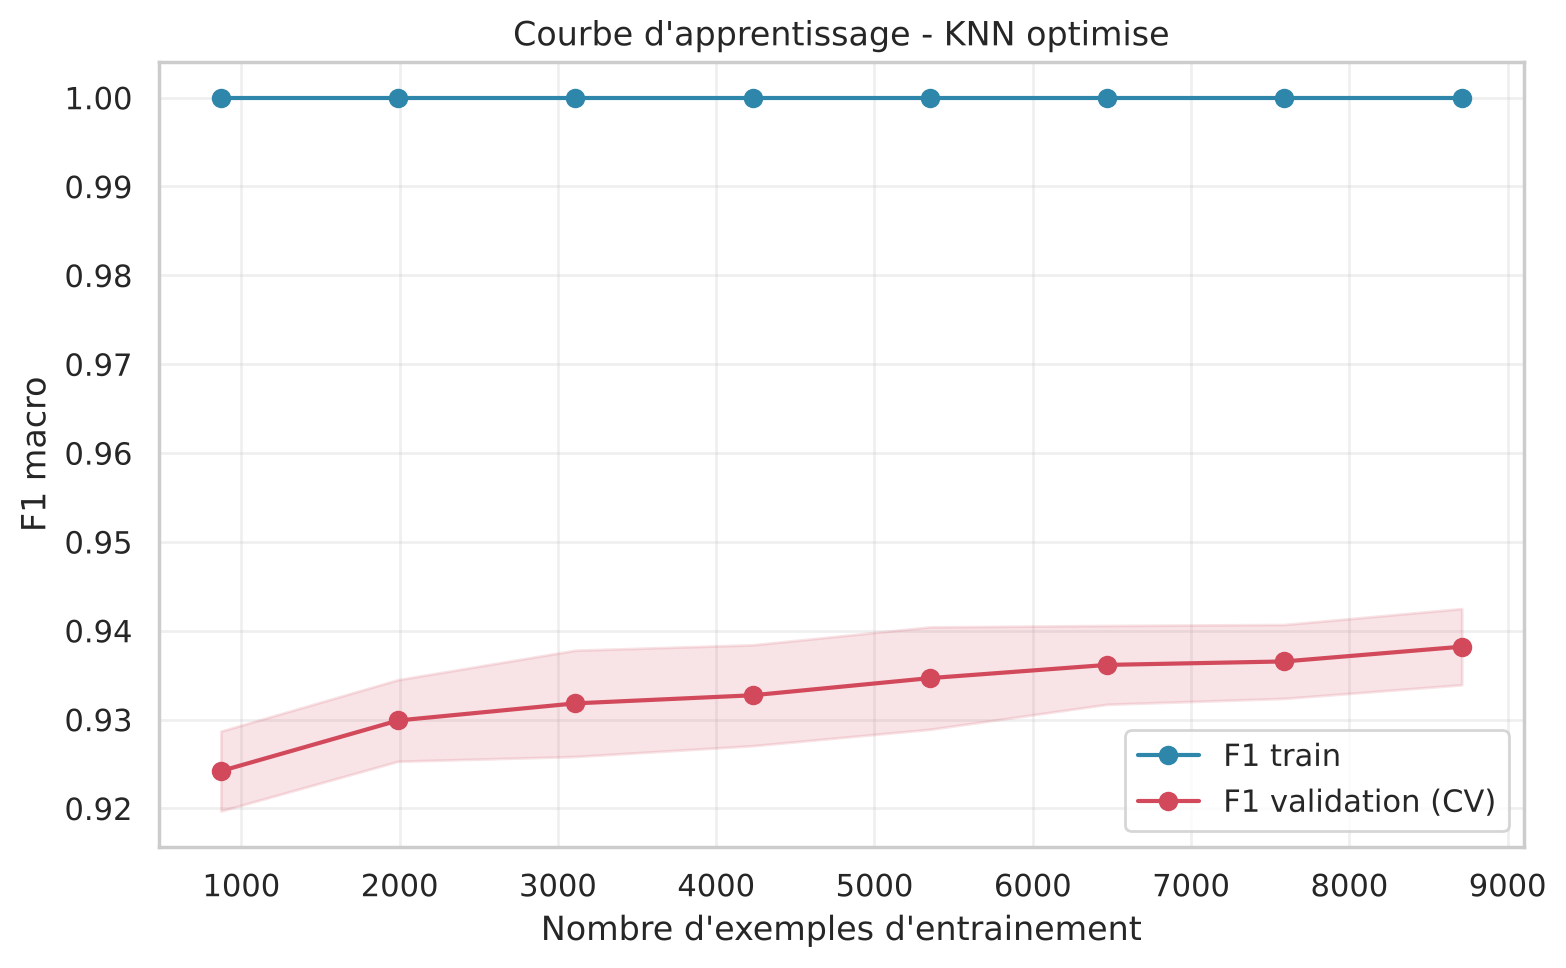

In [16]:
sizes = np.linspace(0.1, 1.0, 8)
train_sizes, train_scores, val_scores = learning_curve(
    best, X_train, y_train,
    train_sizes=sizes, cv=cv, scoring="f1_macro", n_jobs=-1, random_state=SEED,
)
train_mean, train_std = train_scores.mean(axis=1), train_scores.std(axis=1)
val_mean,   val_std   = val_scores.mean(axis=1),   val_scores.std(axis=1)

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_mean, "o-", color="#2e86ab", label="F1 train")
plt.fill_between(train_sizes, train_mean-train_std, train_mean+train_std, alpha=0.15, color="#2e86ab")
plt.plot(train_sizes, val_mean, "o-", color="#d1495b", label="F1 validation (CV)")
plt.fill_between(train_sizes, val_mean-val_std, val_mean+val_std, alpha=0.15, color="#d1495b")
plt.xlabel("Nombre d'exemples d'entrainement"); plt.ylabel("F1 macro")
plt.title("Courbe d'apprentissage - KNN optimise")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

**Lecture :**
- La courbe `F1 validation` **plafonne** autour de 0.93 : rajouter des donnees ne ferait gagner que quelques millimes.
- La courbe `F1 train` est constante a **1.00** : normal pour KNN avec `weights="distance"`, le plus proche voisin d'un point du train est **lui-meme** (distance = 0 → poids infini). Ce n'est **pas** un bug, ni un surapprentissage classique.

## 10. BONUS 4 — Temps de prediction et analyse d'erreurs

**Temps de prediction :** KNN est reputee lente a l'inference. Verifions sur nos 2 723 grains.

In [17]:
t0 = time.time()
_ = best.predict(X_test)
dt = time.time() - t0
print(f"Prediction de {len(X_test)} grains : {dt*1000:.1f} ms  ({dt/len(X_test)*1000:.3f} ms/grain)")
print(f"Debit : environ {len(X_test)/dt:.0f} grains par seconde")

Prediction de 2723 grains : 47.8 ms  (0.018 ms/grain)
Debit : environ 56910 grains par seconde


**Verdict :** a cette taille, KNN reste rapide. Ca deviendrait un probleme sur des millions d'exemples en production (le modele doit comparer chaque nouveau grain aux ~11 000 grains du train).

**Analyse d'erreurs :** regardons concretement 5 grains que le modele a mal classes.

In [18]:
mask = (y_pred != y_test.values)
err = X_test.copy(); err["vraie"] = y_test.values; err["predite"] = y_pred
err = err[mask]
print(f"Erreurs totales : {mask.sum()} / {len(y_test)} ({mask.sum()/len(y_test)*100:.1f} %)")
err.sample(5, random_state=SEED)[["vraie", "predite", "Area", "Perimeter", "AspectRation", "Compactness"]].round(3)

Erreurs totales : 225 / 2723 (8.3 %)


,vraie,predite,Area,Perimeter,AspectRation,Compactness
7436,SIRA,DERMASON,33493,683.487,1.492,0.817
7618,SIRA,DERMASON,38169,735.359,1.564,0.798
1895,SEKER,SIRA,47762,816.963,1.417,0.839
2659,BARBUNYA,CALI,68999,1012.123,1.737,0.757
3872,CALI,SEKER,45666,789.770,1.297,0.877


## 11. Conclusion

| Indicateur | Valeur |
|---|---|
| Meilleurs hyperparametres | `n_neighbors=9`, `metric="euclidean"`, `weights="distance"` |
| F1 macro CV (train) | **0.9382** |
| **F1 macro test** | **0.9300** |
| Accuracy test | 0.9174 |
| Gain de la standardisation | **+0.22 F1 macro** |
| Baseline naive (stratified) | F1 ≈ 0.15 |
| Classe parfaite | BOMBAY (F1 = 1.00) |
| Classe difficile | SIRA (F1 = 0.86) |

**Verdict :** modele robuste, ecart train/test faible, interpretable. Les limites (confusion DERMASON ↔ SIRA) sont **explicables** par la morphologie tres proche de ces deux varietes et seraient levees avec de nouvelles caracteristiques (couleur, texture) qui ne sont pas dans ce dataset.

Pour l'equipe, les chiffres a comparer avec les autres modeles sont **0.9300 (F1 macro test)** et **0.9174 (accuracy test)**.

---

*Toutes les explications pedagogiques (c'est quoi le ML, PCA, F1, learning curve...) sont dans `EXPLICATIONS_DETAILLEES.md`.*
